# Homework #1 - Sistemi Informativi Evoluti e Big Data (2025-2026) 
## Amazon Fine Food Reviews - MongoDB
Camossi Filippo (734170)

Questo notebook implementa l'analisi completa del dataset [Amazon Fine Food Reviews](https://www.kaggle.com/datasets/snap/amazon-fine-food-reviews) utilizzando MongoDB.

## Setup - Installazione delle librerie necessarie

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import time
import warnings

# Librerie MongoDB
from pymongo import MongoClient

# Analisi del sentiment
from vaderSentiment.vaderSentiment import SentimentIntensityAnalyzer

# Machine Learning
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity
from sklearn.preprocessing import MinMaxScaler

# Configurazione
warnings.filterwarnings('ignore')

## 1. Caricamento dei Dati

### 1.1 Connessione al Database

Carichiamo il dataset e lo organizziamo in collezioni separate per ogni livello di score (1-5) e una collezione per i record senza testo.

In [2]:
# Connessione a MongoDB
client = MongoClient('mongodb://localhost:27017/')
db = client['amazon_food_reviews']

print("Connesso a MongoDB con successo")
print(f"Database: {db.name}")

Connesso a MongoDB con successo
Database: amazon_food_reviews


### Pulizia DB per esecuzioni ripetute

In [3]:
# Pulizia per esecuzioni ripetute
db.drop_collection("score_1")
db.drop_collection("score_2")
db.drop_collection("score_3")
db.drop_collection("score_4")
db.drop_collection("score_5")
db.drop_collection("no_text")

{'nIndexesWas': 1, 'ns': 'amazon_food_reviews.no_text', 'ok': 1.0}

## 2. Sentiment Analysis

Utilizzo di VADER (Valence Aware Dictionary and sEntiment Reasoner) per analizzare il sentiment delle recensioni.

In [4]:
analyzer = SentimentIntensityAnalyzer()

def get_sentiment(text):
    """
    Analizza il sentiment di un testo usando VADER e lo classifica
    """
    # VADER calcola un punteggio 'compound' da -1 (neg) a +1 (pos)
    compound_score = analyzer.polarity_scores(text)['compound']
    
    # Classificazione secondo le soglie ottenute da Grid Search su 50k campioni (10k per score)
    if compound_score >= 0.53:
        return "positive"
    elif compound_score <= -0.20:
        return "negative"
    else:
        return "neutral"

### 1.2 Preparazione dati

In [5]:
# carica SOLO le colonne che servono dal CSV
COLUMNS_TO_LOAD = [
    'ProductId', 'UserId', 'ProfileName', 
    'Score', 'Summary', 'Text', 'Time'
]

# definisce la mappatura per rinominare le colonne
COLUMN_MAP = {
    'ProductId': 'product_id',
    'UserId': 'user_id',
    'ProfileName': 'profile_name',
    'Score': 'score',
    'Summary': 'summary',
    'Text': 'text',
    'Time': 'time'
}

# Caricamento e Preparazione Dati (in Pandas)
print("Caricamento Reviews.csv...")
# Carica SOLO le colonne necessarie
df = pd.read_csv("Reviews.csv", usecols=COLUMNS_TO_LOAD)
# Rinomina le colonne
df.rename(columns=COLUMN_MAP, inplace=True)

# Pulizia 'Score' -> solo Intger
df['score'] = pd.to_numeric(df['score'], errors='coerce').astype('Int8')
# Pulizia 'Summary' e 'Text' -> solo String
df['summary'] = df['summary'].fillna('').astype(str)
df['text'] = df['text'].fillna('').astype(str)
# Conversione 'Time' -> Secondi trascorsi dal 01/01/1970
df['time'] = pd.to_datetime(df['time'], unit='s', errors='coerce')

# Analisi Sentiment
print("Esecuzione Analisi del Sentiment (VADER)...")
start_time = time.time()
df['sentiment'] = df['text'].apply(get_sentiment)
elapsed = time.time() - start_time

print(f"Analisi del Sentiment completata in {elapsed:.2f} secondi.")
print("Dati preparati.")

Caricamento Reviews.csv...
Esecuzione Analisi del Sentiment (VADER)...
Analisi del Sentiment completata in 151.31 secondi.
Dati preparati.


### 1.3 Validator e Caricamento Dati in MongoDB

In [6]:
# Lo score deve essere obbligatorio per poter classificare le recensioni
# summary e text devono essere stringhe non vuote altrimenti classifico in "no_text"

review_validator = {
    '$jsonSchema': {
        'bsonType': 'object',
        'required': ['score', 'summary', 'text'],
        'properties': {
            'score': {
                'bsonType': 'int',
                'minimum': 1,
                'maximum': 5,
            },
            'summary': {
                'bsonType': 'string',
                "minLength": 1
            },
            'text': {
                'bsonType': 'string',
                "minLength": 1
            }
        }
    }
}

col_score_1 = db.create_collection("score_1", validator=review_validator)
col_score_2 = db.create_collection("score_2", validator=review_validator)
col_score_3 = db.create_collection("score_3", validator=review_validator)
col_score_4 = db.create_collection("score_4", validator=review_validator)
col_score_5 = db.create_collection("score_5", validator=review_validator)
col_no_text = db.create_collection("no_text")

reviews = df.to_dict(orient="records")

start_time = time.time()

for review in reviews:
    score = int(review.get("score"))
    if score == 1:
        try:
            col_score_1.insert_one(review)
        except:
            col_no_text.insert_one(review)
    elif score == 2:
        try:
            col_score_2.insert_one(review)
        except:
            col_no_text.insert_one(review)
    elif score == 3:
        try:
            col_score_3.insert_one(review)
        except:
            col_no_text.insert_one(review)
    elif score == 4:
        try:
            col_score_4.insert_one(review)
        except:
            col_no_text.insert_one(review)
    elif score == 5:
        try:
            col_score_5.insert_one(review)
        except:
            col_no_text.insert_one(review)
    else:
        col_no_text.insert_one(review)

elapsed = time.time() - start_time
print("Caricamento completato con Validator")
print(f"Tempo di esecuzione: {elapsed:.4f} secondi")

Caricamento completato con Validator
Tempo di esecuzione: 38.2263 secondi


## 3. Interrogazioni Analitiche

### Query 1: Numero di recensioni per ciascun valore di score

>Trovare il numero di recensioni per ciascun valore di score e visualizzarlo in un istogramma

Numero di recensioni per score:

Score 1:   52268 recensioni
Score 2:   29744 recensioni
Score 3:   42638 recensioni
Score 4:   80655 recensioni
Score 5:  363122 recensioni


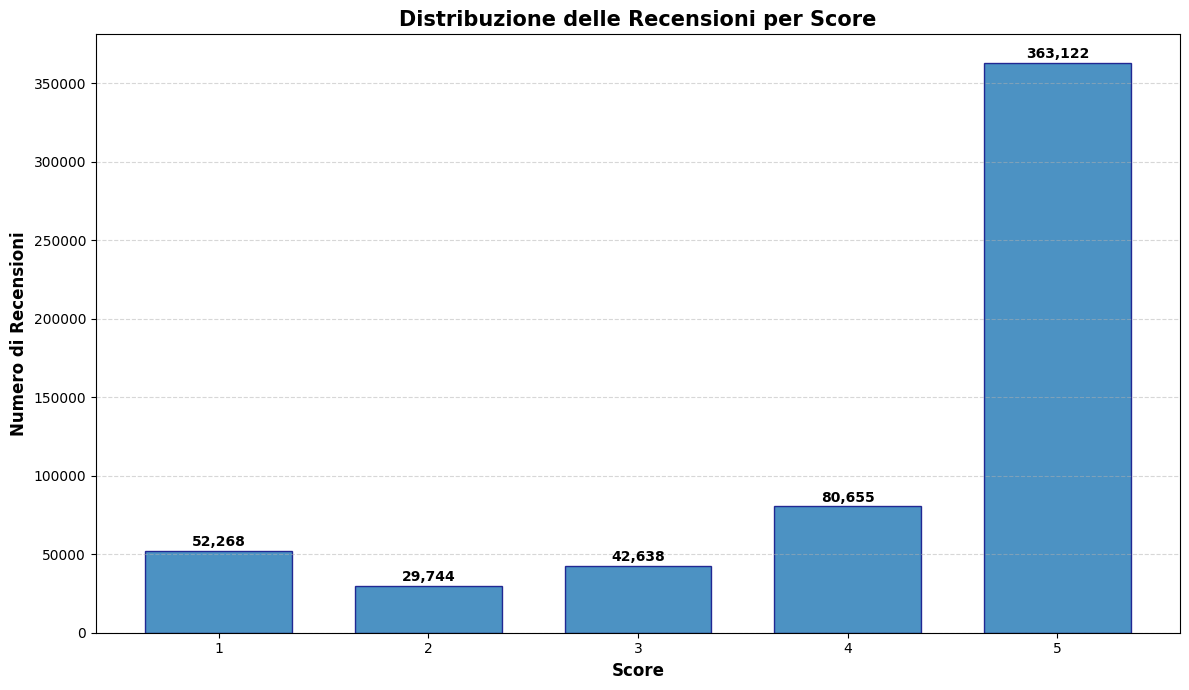


Query completata in 0.1315 secondi.



In [7]:
score_counts = {}

start_time = time.time()
for i in range(1, 6):
    count = db[f'score_{i}'].count_documents({})
    score_counts[i] = count

elapsed = time.time() - start_time

print("Numero di recensioni per score:\n")
for score, count in sorted(score_counts.items()):
    print(f"Score {score}: {count:7d} recensioni")

# Visualizzazione con istogramma
fig, ax = plt.subplots(figsize=(12, 7))
scores = list(score_counts.keys())
counts = list(score_counts.values())

bars = ax.bar(scores, counts, edgecolor='navy', alpha=0.8, width=0.7)

# Aggiungi valori sopra le barre
for bar in bars:
    height = bar.get_height()
    ax.text(bar.get_x() + bar.get_width()/2., height + 1000,
            f'{int(height):,}',
            ha='center', va='bottom', fontsize=10, fontweight='bold')

ax.set_xlabel('Score', fontsize=12, fontweight='bold')
ax.set_ylabel('Numero di Recensioni', fontsize=12, fontweight='bold')
ax.set_title('Distribuzione delle Recensioni per Score', fontsize=15, fontweight='bold')
ax.set_xticks(scores)
ax.grid(axis='y', alpha=0.5, linestyle='--')
plt.tight_layout()
plt.show()

print(f"\nQuery completata in {elapsed:.4f} secondi.\n")

### Query 2: Top 5 prodotti con la media di score più alta

>Trovare i 5 prodotti con la media di *score* più alta

In [ ]:
# Pipeline di aggregazione che unisce tutte le collezioni e calcola medie
pipeline = [
    # Unisci tutte le collezioni score_2 attraverso score_5
    {"$unionWith": {"coll": "score_2"}},
    {"$unionWith": {"coll": "score_3"}},
    {"$unionWith": {"coll": "score_4"}},
    {"$unionWith": {"coll": "score_5"}},
    
    # Raggruppa per product_id e calcola statistiche
    {
        "$group": {
            "_id": "$product_id",
            "avg_score": {"$avg": "$score"},
            "num_reviews": {"$sum": 1},
            "min_score": {"$min": "$score"},
            "max_score": {"$max": "$score"}
        }
    },
    
    # Ordina per media score decrescente e numero recensioni decrescente
    {"$sort": {"avg_score": -1, "num_reviews": -1}},
    
    # Prendi top 5
    {"$limit": 5}
]

# Esegui aggregation su MongoDB
start_time = time.time()

try:
    top_5_products = list(db.score_1.aggregate(pipeline, allowDiskUse=True))
    elapsed = time.time() - start_time

    print("Top 5 Prodotti con Media Score più Alta:\n")
    for i, prod in enumerate(top_5_products, 1):
        print(f"{i}. Product ID: {prod['_id']}")
        print(f"   Media Score: {prod['avg_score']:.3f}")
        print(f"   Numero Recensioni: {prod['num_reviews']:,}")
        print(f"   Range: {prod['min_score']} - {prod['max_score']}")
        print("-"*40)

except Exception as e:
    print(f"Errore durante l'aggregazione: {e}")
    
print(f"\nQuery completata in {elapsed:.4f} secondi.\n")


Top 5 Prodotti con Media Score più Alta:

1. Product ID: B000RL53PE
   Media Score: 5.000
   Numero Recensioni: 33
   Range: 5 - 5
----------------------------------------
2. Product ID: B005EL6VOY
   Media Score: 5.000
   Numero Recensioni: 33
   Range: 5 - 5
----------------------------------------
3. Product ID: B001IZ9ME6
   Media Score: 5.000
   Numero Recensioni: 31
   Range: 5 - 5
----------------------------------------
4. Product ID: B00376ZEY6
   Media Score: 5.000
   Numero Recensioni: 30
   Range: 5 - 5
----------------------------------------
5. Product ID: B0029O0XGQ
   Media Score: 5.000
   Numero Recensioni: 30
   Range: 5 - 5
----------------------------------------

Query completata in 0.3247 secondi.



### Query 3: Top 5 utenti che hanno scritto più recensioni

>Trovare i 5 utenti che hanno scritto più recensioni

In [9]:
pipeline = [
    # unisci TUTTE le 6 collezioni (incluse 'no_text')
    {"$unionWith": {"coll": "score_2"}},
    {"$unionWith": {"coll": "score_3"}},
    {"$unionWith": {"coll": "score_4"}},
    {"$unionWith": {"coll": "score_5"}},
    {"$unionWith": {"coll": "no_text"}},  # Query sugli utenti non direttamente sulle recensioni
    
    # raggruppa per utente.
    {
        "$group": {
            "_id": "$user_id",
            "count": {"$sum": 1},
            "profile_name": {"$first": "$profile_name"} # Prende il primo nome che trova
        }
    },

    # ordina per conteggio
    {"$sort": {"count": -1}},
    
    # Prende i primi 5
    {"$limit": 5}
]

print("Top 5 Utenti con Più Recensioni (Query Ottimizzata):\n")

start_time = time.time()
# esegue query di aggregazione
try:
    top_5_users = list(db.score_1.aggregate(pipeline, allowDiskUse=True))
    elapsed = time.time() - start_time

    for i, user in enumerate(top_5_users, 1):
        print(f"{i}. User ID: {user['_id']}")
        print(f"   Profile Name: {user['profile_name']}")
        print(f"   Numero Recensioni: {user['count']:,}")
        print("-"*50)

except Exception as e:
    print(f"Errore durante l'aggregazione: {e}")

print(f"\nQuery completata in {elapsed:.4f} secondi.\n")

Top 5 Utenti con Più Recensioni (Query Ottimizzata):

1. User ID: A3OXHLG6DIBRW8
   Profile Name: C. F. Hill "CFH"
   Numero Recensioni: 448
--------------------------------------------------
2. User ID: A1YUL9PCJR3JTY
   Profile Name: O. Brown "Ms. O. Khannah-Brown"
   Numero Recensioni: 421
--------------------------------------------------
3. User ID: AY12DBB0U420B
   Profile Name: Gary Peterson
   Numero Recensioni: 389
--------------------------------------------------
4. User ID: A281NPSIMI1C2R
   Profile Name: Rebecca of Amazon "The Rebecca Review"
   Numero Recensioni: 365
--------------------------------------------------
5. User ID: A1Z54EM24Y40LL
   Profile Name: c2
   Numero Recensioni: 256
--------------------------------------------------

Query completata in 0.4868 secondi.



### Query 4: Numero di recensioni positive, neutre e negative per ogni score

>Calcolare il numero di recensioni positive, neutre e negative per ogni valore di *score* (usando l’attributo *sentiment*)

Distribuzione del Sentiment per Score:

Score    Positive        Neutral         Negative        Total     
1        16,448          14,468          21,352          52,268    
2        13,629          8,381           7,734           29,744    
3        26,189          10,480          5,969           42,638    
4        66,051          10,955          3,649           80,655    
5        320,939         33,434          8,749           363,122   
-----------------------------------------------------------------


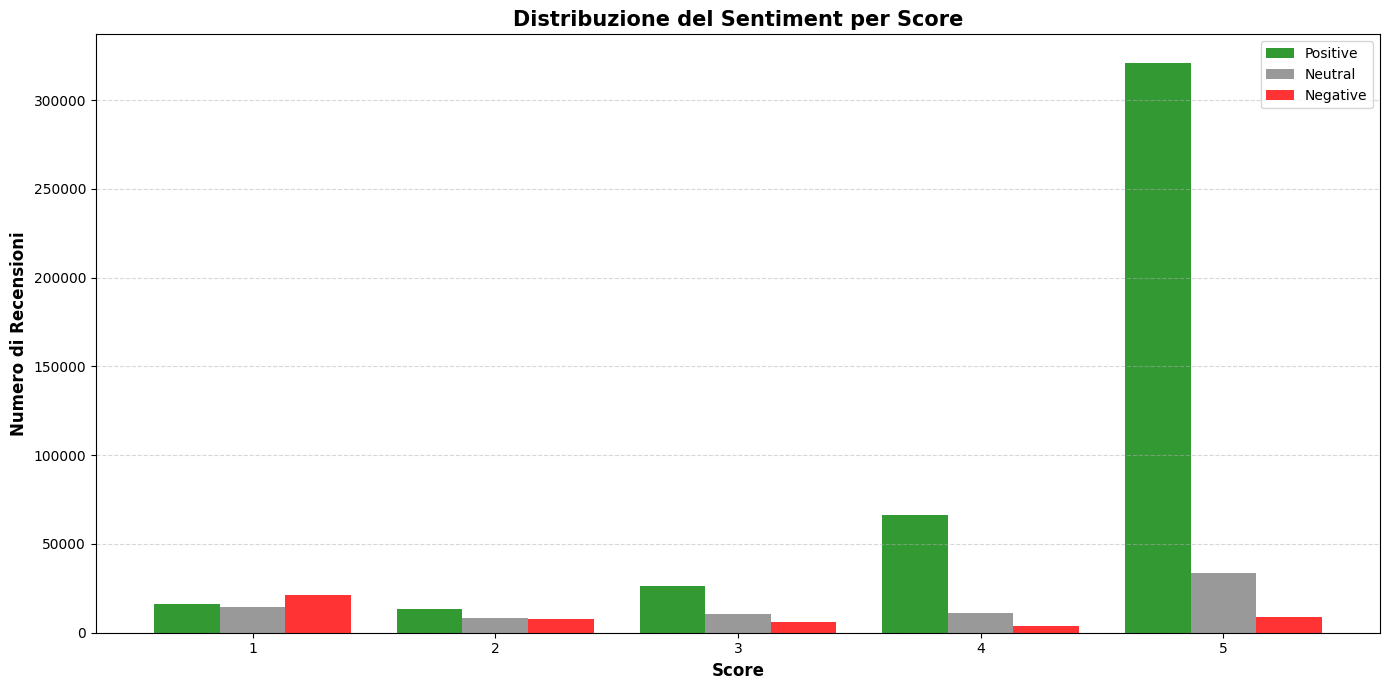

Tempo totale esecuzione query: 0.1273 secondi



In [ ]:
sentiment_by_score = {}

total_start_time = time.time()

for score in range(1, 6):
    pipeline = [
        {
            '$group': {
                '_id': '$sentiment',
                'count': {'$sum': 1}
            }
        }
    ]
    results = list(db[f'score_{score}'].aggregate(pipeline))
    
    # converti la lista di risultati in un dizionario
    # [{'id': 'positive', 'count': 100}] -> {'positive': 100}
    counts_dict = {res['_id']: res['count'] for res in results if res['_id']}
    
    # assegna i valori
    sentiment_by_score[score] = {
        'positive': counts_dict.get('positive', 0),
        'neutral': counts_dict.get('neutral', 0),
        'negative': counts_dict.get('negative', 0)
    }

elapsed = time.time() - total_start_time

print("Distribuzione del Sentiment per Score:\n")
print(f"{'Score':<8} {'Positive':<15} {'Neutral':<15} {'Negative':<15} {'Total':<10}")

for score in range(1, 6):
    pos = sentiment_by_score[score]['positive']
    neu = sentiment_by_score[score]['neutral']
    neg = sentiment_by_score[score]['negative']
    total = pos + neu + neg
    
    print(f"{score:<8} {pos:<15,} {neu:<15,} {neg:<15,} {total:<10,}")

# Visualizzazione grafico a barre
scores = list(range(1, 6))
positive_counts = [sentiment_by_score[s]['positive'] for s in scores]
neutral_counts = [sentiment_by_score[s]['neutral'] for s in scores]
negative_counts = [sentiment_by_score[s]['negative'] for s in scores]

x = np.arange(len(scores))
width = 0.27

fig, ax = plt.subplots(figsize=(14, 7))
bars1 = ax.bar(x - width, positive_counts, width, label='Positive', color='green', alpha=0.8)
bars2 = ax.bar(x, neutral_counts, width, label='Neutral', color='gray', alpha=0.8)
bars3 = ax.bar(x + width, negative_counts, width, label='Negative', color='red', alpha=0.8)

ax.set_xlabel('Score', fontsize=12, fontweight='bold')
ax.set_ylabel('Numero di Recensioni', fontsize=12, fontweight='bold')
ax.set_title('Distribuzione del Sentiment per Score', fontsize=15, fontweight='bold')
ax.set_xticks(x)
ax.set_xticklabels(scores)
ax.legend()
ax.grid(axis='y', alpha=0.5, linestyle='--')

plt.tight_layout()
plt.show()

print(f"Tempo totale esecuzione query: {elapsed:.4f} secondi\n")

### Query 5: Prodotti con alto score medio (>=4.5) ma almeno 10% sentiment negativo

>Trovare i prodotti che hanno sia un alto punteggio medio (*score* >= 4.5) che recensioni con almeno il 10% di sentiment negativo

In [ ]:
pipeline = [
    # unisci le 5 collezioni
    {"$unionWith": {"coll": "score_2"}},
    {"$unionWith": {"coll": "score_3"}},
    {"$unionWith": {"coll": "score_4"}},
    {"$unionWith": {"coll": "score_5"}},
    
    # raggruppa per prodotto
    {
        "$group": {
            "_id": "$product_id",
            "avg_score": {"$avg": "$score"},
            "total_reviews": {"$sum": 1},
            "negative_count": {
                "$sum": {
                    "$cond": [ {"$eq": ["$sentiment", "negative"]}, 1, 0 ]
                }
            }
        }
    },

    # aggiungi 'negative_pct'
    # prima non si può fare perchè 'total_reviews' e 'negative_count' non esistono
    {
        "$addFields": {
            "negative_pct": {
                "$multiply": [ 
                        {"$divide": ["$negative_count", "$total_reviews"]},
                    100 
                ]
            }
        }
    },
    
    # filtra per i criteri richiesti
    {
        "$match": {
            {"$gte": ["$avg_score", 4.5]},
            {"$gte": ["$negative_pct", 10.0]}
        }
    },

    # Ordina per % negativa
    {"$sort": {"negative_pct": -1}}
]

print(f"Prodotti con Score Medio >= 4.5 e almeno 10% Sentiment Negativo:\n")

start_time = time.time()
try:
    # inizia da 'score_1' e unisce le altre
    qualifying_products = list(db.score_1.aggregate(pipeline, allowDiskUse=True))
    elapsed = time.time() - start_time

    print(f"Trovati {len(qualifying_products)} prodotti (Tempo: {elapsed:.4f}s)\n")

    if len(qualifying_products) > 0:
        print(f"{'Product ID':<20} {'Avg Score':>10} {'Reviews':>8} {'Neg':>6} {'Neg %':>8}\n")

        for prod in qualifying_products[:20]: # mostra i primi 20
            print(f"{prod['_id']:<20} "
                    f"{prod['avg_score']:>10.2f} "
                    f"{prod['total_reviews']:>8} "
                    f"{prod['negative_count']:>6} "
                    f"{prod['negative_pct']:>7.1f}%")
    else:
        print("Nessun prodotto soddisfa i criteri specificati.")

except Exception as e:
    print(f"Errore durante l'aggregazione: {e}")

print(f"\nTempo totale esecuzione query: {elapsed:.4f} secondi\n")

Prodotti con Score Medio >= 4.5 e almeno 10% Sentiment Negativo:

Trovati 464 prodotti (Tempo: 0.3478s)

Product ID            Avg Score  Reviews    Neg    Neg %
------------------------------------------------------------
B000FBMFDO                 4.62       97     57    58.8%
B000EPOBYC                 4.54       13      4    30.8%
B000WAFJ0E                 4.50       10      3    30.0%
B0029J6JI2                 4.70       10      3    30.0%
B001JU7YJA                 4.50       10      3    30.0%
B0009F3QLQ                 4.62       50     15    30.0%
B000EF3E3Q                 4.60       10      3    30.0%
B000WAC1F0                 4.50       10      3    30.0%
B0014ET1S8                 4.50       14      4    28.6%
B0000DG56P                 4.55       11      3    27.3%
B001EQ4VXG                 4.91       11      3    27.3%
B001OCBSS6                 4.64       11      3    27.3%
B002UZSO2O                 4.73       11      3    27.3%
B000CBFTC6                 4.85     

### Discussione sull'Architettura del Database 

La scelta di suddividere le recensioni in sei collezioni distinte (`score_1`...`score_5` e `no_text`) si è rivelata un **ostacolo complesso** per lo svolgimento delle query.

Se da un lato questa struttura ha senso per isolare i dati per un singolo score, ha complicato enormemente qualsiasi analisi che richiedesse una visione d'insieme.

---

### a) Impatto sulla Complessità delle Query

La suddivisione ha aumentato la complessità di quasi tutte le query analitiche.

* **Query Semplici (Query 1 e 4):** Per rispondere a domande "per score" è stata implementata la logica in Python. Sono state eseguite **5 query di aggregazione separate** (una per collezione) e poi uniti i risultati manualmente nello script per generare la tabella e il grafico.

* **Query Complesse (Query 2, 3 e 5):** Per le query che dovevano analizzare *tutti* i dati (top prodotti, top utenti), la complessità è esplosa. L'unica soluzione performante lato database è stata l'uso dell'operatore **`$unionWith`**. Questo ha reso le pipeline macchinose, richiedendo 4-5 stage di unione *prima* di poter iniziare la vera logica analitica (`$group`, `$match`).

Con una collezione unica `reviews`, ogni query sarebbe stata una singola pipeline di aggregazione, più semplice da scrivere, leggere e manutenere.

---

### b) Impatto su Prestazioni e Risorse

Le prestazioni sono calate a causa di questa scelta, sia lato client che lato database.

* **Overhead delle Query:** L'esecuzione di 5 query separate (Query 1 e 4) implica 5 round-trip di rete tra l'applicazione e il database, un overhead non necessario.
* **Overhead di `$unionWith`:** L'uso di `$unionWith` (Query 2, 3, 5) non è a costo zero. Obbliga MongoDB a gestire e unire 5-6 cursori/flussi di dati diversi prima di procedere. Questo è più lento e richiede più CPU e RAM **lato server** rispetto a una singola aggregazione su una collezione unica.
* **Vantaggio Annullato:** L'unico vantaggio sarebbe un *filtering automatico* per score (collezione = score). Tuttavia, le query richieste hanno dimostrato che quasi tutte le analisi cercavano dati *da tutte* le collezioni.

---

### c) Impatto su Manutenibilità e Scalabilità

Questo è l'aspetto più problematico a lungo termine.

* **Manutenibilità:** L'approccio è quasi ingestibile.
    * **Schema:** Qualsiasi modifica allo schema (es. aggiungere un campo) deve essere replicata su **TUTTE** le collezioni.
    * **Indici:** Ogni indice necessario (su `product_id`, `user_id`, `time`) deve essere creato e mantenuto su **TUTTE** le collezioni, aumentando l'uso dello spazio sul disco per gli indici e il costo (CPU/RAM) di ogni operazione di scrittura.
* **Scalabilità:** La scalabilità è *peggiore*.
    * **Sharding:** Tentare di fare "sharding" (distribuzione dei dati) basandosi sullo score sarebbe un disastro. Si creerebbe un **"hot shard"**, poiché la collezione `score_5` (con ~65% dei dati) riceverebbe la maggior parte del traffico, mentre lo shard `score_2` sarebbe quasi inutilizzato.
    * **Crescita:** Con la crescita del dataset, la gestione di decine di collezioni (se si decidesse di partizionare ulteriormente) diventerebbe impossibile.

---

### Confronto con una Collezione Unica Indicizzata

Una singola collezione `reviews` è la soluzione preferibile. La strategia corretta non è il partizionamento *fisico* (collezioni multiple), ma il partizionamento *logico* tramite **indici**.

Mantenendo tutti i ~568.000 documenti in un'unica collezione `reviews`, si potrebbero creare i seguenti indici:

```javascript
// Indice per filtrare/raggruppare per score
db.reviews.createIndex({ score: 1 })

// Indice per filtrare/raggruppare per sentiment
db.reviews.createIndex({ sentiment: 1 })

// Indice per raggruppare per prodotto
db.reviews.createIndex({ product_id: 1 })

```

Con questa struttura:

1. Le query sarebbero più semplici (pipeline singole, senza `$unionWith`).

2. Le performance aumenterebbero, poiché il query planner di MongoDB potrebbe usare questi indici per accedere direttamente ai dati necessari, senza scansioni complete o unioni tra collezioni.

3. La manutenibilità sarebbe banale (uno schema, un set di indici da gestire in un solo posto).

---

#### Scenari d'Uso Corretti

Casi Utili per Collezioni Multiple:

1. Dati "Caldi" vs "Freddi": Separare i dati recenti (es. `reviews_2025`, su cui si fanno query frequenti) da quelli storici (es. `reviews_archive_2010_2020`, interrogati di rado).

2. Diverse Politiche di Retention (TTL): Avere collezioni separate per dati che scadono in tempi diversi (es. `log_eventi_30giorni` vs `log_audit_7anni`).

3. Isolamento del Working Set: Se i dati appartengono a "tenant" (clienti) diversi che non vengono mai aggregati tra loro (es. `dati_cliente_A` e `dati_cliente_B`).
4. Schema Davvero Diverso: Quando i documenti rappresentano entità diverse (es. users e products).

#### Casi Sbagliati per Collezioni Multiple:

1. Dati con Schema Identico: Se i documenti hanno la stessa struttura.

2. Query Analitiche/Aggregative: Se hai bisogno di aggregare dati tra i diversi "silos".

3. Partizionamento su Campi a Bassa Cardinalità: Usare un campo come `score` (con solo 5-6 valori) come chiave di partizionamento fisico è un anti-pattern.

## 4. Sistema di Raccomandazione

Implementazione di un sistema ibrido che combina collaborative filtering e content-based filtering.

si basa su 3 criteri principali:

* co-occorrenza di utenti (utenti che hanno recensito anche altri prodotti);
* media dei sentiment positivi associati ai prodotti;
* somiglianza lessicale tra i testi delle recensioni (ad es. con TfidfVectorizer e
cosine_similarity).

In [ ]:
# Prodotto target per il quale generare raccomandazioni
TARGET_PRODUCT_ID = "B007JFMH8M"
                    # B002QWP89S
                    # B002QWP8H0
                    # B002QWHJOU
                    # B0026RQTGE

ALL_COLLECTION_NAMES = [f'score_{i}' for i in range(1, 6)]

TOP_CANDIDATES = 100   # Numero di candidati da analizzare

# Pesi per i 3 criteri
W_COLLABORATIVE = 0.3  # Peso della "saggezza della folla"
W_CONTENT = 0.4        # Peso della somiglianza testuale (TF-IDF)
W_SENTIMENT = 0.3      # Peso della qualità globale (sentiment)

### Passaggio 1: Identificazione degli Utenti (Parte Collaborativa)

Trova tutti gli utenti che hanno recensito positivamente (score 4 o 5) `TARGET_PRODUCT_ID`

In [13]:
def get_positive_users(db, product_id):
    pipeline = [
        # Filtra per prodotto target
        {"$match": {"product_id": product_id}},
        
        # Unisci score_5 (filtrando anche lì)
        {"$unionWith": {
            "coll": "score_5",
            "pipeline": [{"$match": {"product_id": product_id}}]
        }},
        
        # Raggruppa per user_id
        {"$group": {"_id": "$user_id"}}
    ]
    
    results = list(db.col_score_4.aggregate(pipeline))
    return [doc['_id'] for doc in results]

user_ids = get_positive_users(db, TARGET_PRODUCT_ID)

if not user_ids:
    print(f"Nessun utente ha recensito positivamente {TARGET_PRODUCT_ID}")

print(f"Utenti positivi trovati: {len(user_ids)}")

Utenti positivi trovati: 624


### Passaggio 2: Estrazione dei Prodotti Candidati (Parte Collaborativa)

A partire da `user_ids` trovare un pool di prodotti con cui hanno interagito (su tutte le collezioni). 
Calcolare il punteggio di co-occorrenza, ovvero quanti utenti unici del pool hanno recensito ciascun prodotto.

"Questo prodotto è rilevante per il gruppo di persone a cui è piaciuto `TARGET_PRODUCT_ID`?"

In [14]:
def get_collaborative_candidates(db, user_ids, target_product_id):
    # Costruisci dinamicamente la pipeline
    pipeline = []
    
    # Filtra la prima collezione
    pipeline.append(
        {"$match": {
            "user_id": {"$in": user_ids},
            "product_id": {"$ne": target_product_id}
        }}
    )
    
    # Aggiungi le altre 4 collezioni con $unionWith
    first_coll = ALL_COLLECTION_NAMES[0]
    for coll_name in ALL_COLLECTION_NAMES[1:]:
        union_stage = {"$unionWith": {
            "coll": coll_name,
            "pipeline": [
                {"$match": {
                    "user_id": {"$in": user_ids},
                    "product_id": {"$ne": target_product_id}
                }}
            ]
        }}
        pipeline.append(union_stage)
        
    # Raggruppa e calcola gli utenti unici
    pipeline.append(
        {"$group": {
            "_id": "$product_id",
            "unique_users": {"$addToSet": "$user_id"}
        }}
    )
    
    # Calcola lo score finale
    pipeline.append(
        {"$project": {
            "_id": 0,
            "product_id": "$_id",
            "collaborative_score": {"$size": "$unique_users"}
        }}
    )
    
    # Ordina e limita
    pipeline.append({"$sort": {"collaborative_score": -1}})
    pipeline.append({"$limit": TOP_CANDIDATES}) # Prende i 'TOP_CANDIDATES' candidati

    results = list(db[first_coll].aggregate(pipeline))
    
    if not results:
        raise ValueError("Nessun prodotto candidato trovato.")
        
    # Converti in DataFrame
    df = pd.DataFrame(results).set_index('product_id')
    return df

# Esecuzione
try:
    df_candidates = get_collaborative_candidates(db, user_ids, TARGET_PRODUCT_ID)
    print(f"Trovati {len(df_candidates)} candidati")
    print(df_candidates.head())
    
    # Salva gli ID per la prossima query
    candidate_ids = df_candidates.index.tolist()

except Exception as e:
    print(e)

Trovati 100 candidati
            collaborative_score
product_id                     
B006MONQMC                    8
B007I7Z3Z0                    6
B007I7YZJK                    6
B0051COPH6                    5
B004JGQ15E                    5


### Estrazione Dati di Contenuto

1. **Sentiment Bilanciato**: calcolato come `(positive - negative) / total`, normalizzato in [0, 1].

2. **Testo Aggregato Positivo**: per l'analisi TF-IDF.

In [ ]:
def get_content_data(db, product_ids):
    """
    Esegue UNA query su 5 collezioni per recuperare
    sentiment_score bilanciato e testo aggregato positivo.
    """
    pipeline = []
    
    # Filtra la prima collezione
    pipeline.append(
        {"$match": {"product_id": {"$in": product_ids}}}
    )

    # Aggiungi le altre 4 collezioni
    first_coll = ALL_COLLECTION_NAMES[0]
    for coll_name in ALL_COLLECTION_NAMES[1:]:
        union_stage = {"$unionWith": {
            "coll": coll_name,
            "pipeline": [{"$match": {"product_id": {"$in": product_ids}}}]
        }}
        pipeline.append(union_stage)

    # Raggruppa per prodotto
    pipeline.append(
        {"$group": {
            "_id": "$product_id",
            
            # Raccogli il testo SOLO se 'positive'
            "positive_texts_array": {"$push": {
                "$cond": [
                    {"$eq": ["$sentiment", "positive"]}, 
                    "$text", 
                    "$$REMOVE"
                ]
            }},
            
            # Conta i positivi
            "positive_count": {"$sum": {
                "$cond": [{"$eq": ["$sentiment", "positive"]}, 1, 0]
            }},
            
            # Conta i negativi
            "negative_count": {"$sum": {
                "$cond": [{"$eq": ["$sentiment", "negative"]}, 1, 0]
            }},
            
            # Conta il totale
            "total_count": {"$sum": 1}
        }}
    )
    
    # Proietta i risultati finali
    pipeline.append(
        {"$project": {
            "_id": 0,
            "product_id": "$_id",
            
            # Unisci il testo in una stringa
            "aggregated_text": {
                "$reduce": {
                    "input": "$positive_texts_array",
                    "initialValue": "",
                    "in": {"$concat": ["$$value", " ", "$$this"]}
                }
            },
            
            # Calcola sentiment bilanciato: (positive - negative) / total
            # Poi normalizza da [-1, 1] a [0, 1] con (score + 1) / 2
            "sentiment_score": {
                "$cond": [
                    {"$eq": ["$total_count", 0]},
                    0.5,  # Neutro se non ci sono recensioni
                    {
                        "$divide": [
                            {
                                "$add": [
                                    {
                                        "$divide": [
                                            {"$subtract": ["$positive_count", "$negative_count"]},
                                            "$total_count"
                                        ]
                                    },
                                    1
                                ]
                            },
                            2
                        ]
                    }
                ]
            }
        }}
    )
    
    results = list(db[first_coll].aggregate(pipeline))
    
    # Converti in DataFrame
    df = pd.DataFrame(results).set_index('product_id')
    return df

# Esecuzione
try:
    df_content = get_content_data(db, candidate_ids)
    
    # unisci i nuovi dati (sentiment, text) al df
    df_final = df_candidates.join(df_content, how="left")
    
    print("Dati di contenuto e sentiment uniti")
    print(df_final.head())
    
except Exception as e:
    print(e)

Dati di contenuto e sentiment uniti
            collaborative_score  \
product_id                        
B006MONQMC                    8   
B007I7Z3Z0                    6   
B007I7YZJK                    6   
B0051COPH6                    5   
B004JGQ15E                    5   

                                              aggregated_text  sentiment_score  
product_id                                                                      
B006MONQMC   This Vitamin Squeeze, while touting vitamins ...         0.910387  
B007I7Z3Z0   I was quite excited to try Lipton's new Tea &...         0.881215  
B007I7YZJK   I was quite excited to try Lipton's new Tea &...         0.881215  
B0051COPH6   I like this baby food because it contains not...         0.937995  
B004JGQ15E   Couple points to make about this.<br /><br />...         0.940878  


### Estrazione del Testo dal Target

Estrarre tutto il testo delle recensioni positive da `TARGET_PRODUCT_ID`

In [16]:
def get_target_text(db, product_id):
    """
    Estrae il testo aggregato 'positive' SOLO per il prodotto target.
    """
    pipeline = []
    
    # Filtra per target E sentiment positivo
    pipeline.append(
        {"$match": {
            "product_id": product_id,
            "sentiment": "positive"
        }}
    )
    
    # Unisci le altre 4 collezioni
    first_coll = ALL_COLLECTION_NAMES[0]
    for coll_name in ALL_COLLECTION_NAMES[1:]:
        union_stage = {"$unionWith": {
            "coll": coll_name,
            "pipeline": [
                {"$match": {
                    "product_id": product_id,
                    "sentiment": "positive"
                }}
            ]
        }}
        pipeline.append(union_stage)
        
    # Raggruppa e concatena il testo
    pipeline.append(
        {"$group": {
            "_id": None,
            "all_texts": {"$push": "$text"}
        }}
    )
    
    # Proietta in una stringa unica
    pipeline.append(
        {"$project": {
            "_id": 0,
            "text": {
                "$reduce": {
                    "input": "$all_texts",
                    "initialValue": "",
                    "in": {"$concat": ["$$value", " ", "$$this"]}
                }
            }
        }}
    )

    result = list(db[first_coll].aggregate(pipeline))
    
    if not result:
        raise ValueError(f"Nessun testo positivo trovato per il target {product_id}")
        
    return result[0]['text']

# Esecuzione
try:
    target_text = get_target_text(db, TARGET_PRODUCT_ID)
    print(f"Testo target caricato ({len(target_text)} caratteri)")
    
except Exception as e:
    print(e)

Testo target caricato (242279 caratteri)


### Passaggio 3: Calcolo della Somiglianza Lessicale (Parte Basata sul Contenuto) (TF-IDF)

In [27]:
# [0] = Target
# [1:] = Candidati
corpus = [target_text] + df_final['aggregated_text'].tolist()

print(f"Corpus creato: 1 documento target + {len(df_final)} documenti candidati.")

# Inizializza Vectorizer
vectorizer = TfidfVectorizer(
    stop_words='english',
    max_df=0.8,
    min_df=2,
    ngram_range=(1, 2)
)

print("Calcolo matrice TF-IDF...")
tfidf_matrix = vectorizer.fit_transform(corpus)

# Calcola similarità del coseno
# Compara il target [0] con tutti i candidati [1:]
similarity_scores = cosine_similarity(tfidf_matrix[0:1], tfidf_matrix[1:])

# Aggiungi i punteggi al DataFrame
df_final['content_score'] = similarity_scores[0] # Estrai la riga

print(df_final[['collaborative_score', 'sentiment_score', 'content_score']].head())

Corpus creato: 1 documento target + 100 documenti candidati.
Calcolo matrice TF-IDF...
            collaborative_score  sentiment_score  content_score
product_id                                                     
B006MONQMC                    8         0.910387       0.008787
B007I7Z3Z0                    6         0.881215       0.010530
B007I7YZJK                    6         0.881215       0.010530
B0051COPH6                    5         0.937995       0.022674
B004JGQ15E                    5         0.940878       0.038774


### Passaggio 5: Normalizzazione, Calcolo del Punteggio Finale e Classifica (Parte Ibrida)

In [29]:
print(f"Pesi: Collaborativo={W_COLLABORATIVE}, Contenuto={W_CONTENT}, Sentiment={W_SENTIMENT}")

# Copiamo per sicurezza
df_ranked = df_final.copy()
score_columns = ['collaborative_score', 'sentiment_score', 'content_score']

# Normalizzazione
print("Normalizzazione punteggi (MinMax)...")
scaler = MinMaxScaler()
df_ranked[score_columns] = scaler.fit_transform(df_ranked[score_columns])

# Calcolo Punteggio Finale
df_ranked['final_score'] = (
    (df_ranked['collaborative_score'] * W_COLLABORATIVE) +
    (df_ranked['content_score'] * W_CONTENT) +
    (df_ranked['sentiment_score'] * W_SENTIMENT)
)

# Ordina per il punteggio finale
df_ranked = df_ranked.sort_values(by='final_score', ascending=False)

# --- Risultato ---
print(f"\nTOP 3 PRODOTTI CONSIGLIATI (alternativi a {TARGET_PRODUCT_ID})")

# Estrai e stampa i primi 3
top_3 = df_ranked.head(3)

for i, (product_id, row) in enumerate(top_3.iterrows()):
    print(f"\n{i+1}. ID Prodotto: {product_id}")
    print(f"   Punteggio Finale: {row['final_score']:.4f}")
    print("   Dettagli Punteggi:")
    print(f"   Collaborativo: {row['collaborative_score']:.4f} (Peso: {W_COLLABORATIVE})")
    print(f"   Contenuto (TF-IDF): {row['content_score']:.4f} (Peso: {W_CONTENT})")
    print(f"   Sentiment: {row['sentiment_score']:.4f} (Peso: {W_SENTIMENT})")

Pesi: Collaborativo=0.3, Contenuto=0.4, Sentiment=0.3
Normalizzazione punteggi (MinMax)...

TOP 3 PRODOTTI CONSIGLIATI (alternativi a B007JFMH8M)

1. ID Prodotto: B000YPIJTU
   Punteggio Finale: 0.6232
   Dettagli Punteggi:
   Collaborativo: 0.1429 (Peso: 0.3)
   Contenuto (TF-IDF): 1.0000 (Peso: 0.4)
   Sentiment: 0.6011 (Peso: 0.3)

2. ID Prodotto: B004U43ZO0
   Punteggio Finale: 0.6115
   Dettagli Punteggi:
   Collaborativo: 0.4286 (Peso: 0.3)
   Contenuto (TF-IDF): 0.7977 (Peso: 0.4)
   Sentiment: 0.5461 (Peso: 0.3)

3. ID Prodotto: B006H34CUS
   Punteggio Finale: 0.5429
   Dettagli Punteggi:
   Collaborativo: 0.1429 (Peso: 0.3)
   Contenuto (TF-IDF): 0.5816 (Peso: 0.4)
   Sentiment: 0.8915 (Peso: 0.3)


### Classificazione del Sistema di Raccomandazione

Il sistema implementato è un **Sistema di Raccomandazione Ibrido (Hybrid Recommender System)**.

Utilizza una strategia **ibrida pesata (weighted hybrid)**, che combina i punteggi di tre diverse tecniche per produrre un'unica classifica finale:

1.  **Collaborative Filtering (Filtro Collaborativo):**
    * **Metodo:** `co-occorrenza di utenti`.
    * **Perché:** Misura la rilevanza specifica. Raccomanda prodotti basandosi sul comportamento di utenti simili (la "saggezza della folla"). Risponde alla domanda: "Quali altri prodotti sono rilevanti per le persone a cui è piaciuto il prodotto target?".

2.  **Content-Based Filtering (Filtro Basato sul Contenuto):**
* Questo approccio misura la qualità intrinseca del prodotto, utilizzando due diversi attributi (contenuti):

    * **Metodo (Testo):** `somiglianza lessicale` (TF-IDF e cosine similarity).
    * **Perché:** Misura la *similarità tematica*. Risponde alla domanda: "Quali altri prodotti sono tematicamente simili al prodotto target?".

    * **Metodo (Qualità):** `media dei sentiment`.
    * **Perché:** Misura la *qualità globale*. Agisce come un filtro, rispondendo alla domanda: "Tra i prodotti candidati, quali sono effettivamente apprezzati dal pubblico generale?".

## 5. Analisi Avanzata - Evoluzione del Sentiment nel Tempo

Analizziamo l'evoluzione temporale del sentiment per i top 5 prodotti.

In [19]:
# Recupera i top 5 prodotti (Query 2)
print("Top 5 prodotti per analisi temporale:")
for i, prod in enumerate(top_5_products, 1):
    print(f"{i}. {prod['_id']} (avg score: {prod['avg_score']:.2f})")

Top 5 prodotti per analisi temporale:
1. B000RL53PE (avg score: 5.00)
2. B005EL6VOY (avg score: 5.00)
3. B001IZ9ME6 (avg score: 5.00)
4. B00376ZEY6 (avg score: 5.00)
5. B0029O0XGQ (avg score: 5.00)


### 5a) Calcolo dell'andamento mensile della proporzione di sentiment

In [30]:
def analyze_temporal_sentiment_agg(db, product_id: str):
    # Nomi di tutte le collezioni da unire
    all_collections = [f'score_{i}' for i in range(1, 6)]
    first_coll_name = all_collections[0]
    
    pipeline = [
        # Filtra la prima collezione
        {"$match": {"product_id": product_id}},
    ]
    # Unisci tutte le altre collezioni (già filtrate)
    for coll_name in all_collections[1:]:
        pipeline.append({
            "$unionWith": {
                "coll": coll_name,
                "pipeline": [{"$match": {"product_id": product_id}}]
            }
        })
    
    # Raggruppa per Mese E per Sentiment
    pipeline.append({
        "$group": {
            "_id": {
                # restituisce una data BSON
                "year_month": {
                    "$dateTrunc": {"date": "$time", "unit": "month"}
                },
                "sentiment": "$sentiment"
            },
            "count": {"$sum": 1}
        }
    })
    
    pipeline.append({
        "$group": {
            "_id": "$_id.year_month",
            "positive": {
                "$sum": {"$cond": [ {"$eq": ["$_id.sentiment", "positive"]}, "$count", 0 ]}
            },
            "neutral": {
                "$sum": {"$cond": [ {"$eq": ["$_id.sentiment", "neutral"]}, "$count", 0 ]}
            },
            "negative": {
                "$sum": {"$cond": [ {"$eq": ["$_id.sentiment", "negative"]}, "$count", 0 ]}
            }
        }
    })
    
    # Ordina cronologicamente
    pipeline.append({"$sort": {"_id": 1}})

    try:
        results = list(db[first_coll_name].aggregate(pipeline, allowDiskUse=True))
        
        if not results:
            return None
            
        # Calcolo %
        df_counts = pd.DataFrame(results).rename(columns={'_id': 'month'}).set_index('month')
        
        # Calcola il totale
        df_counts['total'] = df_counts.sum(axis=1)

        # Calcola percentuali
        df_pct = pd.DataFrame(index=df_counts.index)
        df_pct['positive'] = (df_counts['positive'] / df_counts['total']) * 100
        df_pct['neutral'] = (df_counts['neutral'] / df_counts['total']) * 100
        df_pct['negative'] = (df_counts['negative'] / df_counts['total']) * 100
        
        # Aggiungiamo il 'total' per l'analisi delle anomalie (punto 5c)
        df_pct['total_reviews'] = df_counts['total']
        
        return df_pct.fillna(0) # Riempi i NaN (dovuti a divisione 0/0)

    except Exception as e:
        print(f"Errore durante l'aggregazione per {product_id}: {e}")
        return None

temporal_data = {}

print("Raccolta dati temporali per i top 5 prodotti...")
start_time_total = time.time()

for prod in top_5_products:
    pid = prod['_id']
    data = analyze_temporal_sentiment_agg(db, pid)
    if data is not None and not data.empty:
        temporal_data[pid] = data
        print(f"{pid}: {len(data)} mesi di dati")
    else:
        print(f"{pid}: NESSUN dato disponibile")
        
elapsed_total = time.time() - start_time_total
print(f"\nAnalisi temporale completata in {elapsed_total:.2f} secondi.")

Raccolta dati temporali per i top 5 prodotti...
B000RL53PE: 22 mesi di dati
B005EL6VOY: 12 mesi di dati
B001IZ9ME6: 20 mesi di dati
B00376ZEY6: 16 mesi di dati
B0029O0XGQ: 16 mesi di dati

Analisi temporale completata in 0.64 secondi.


### 5b) Visualizzazione Grafica dell'Evoluzione del Sentiment nel Tempo

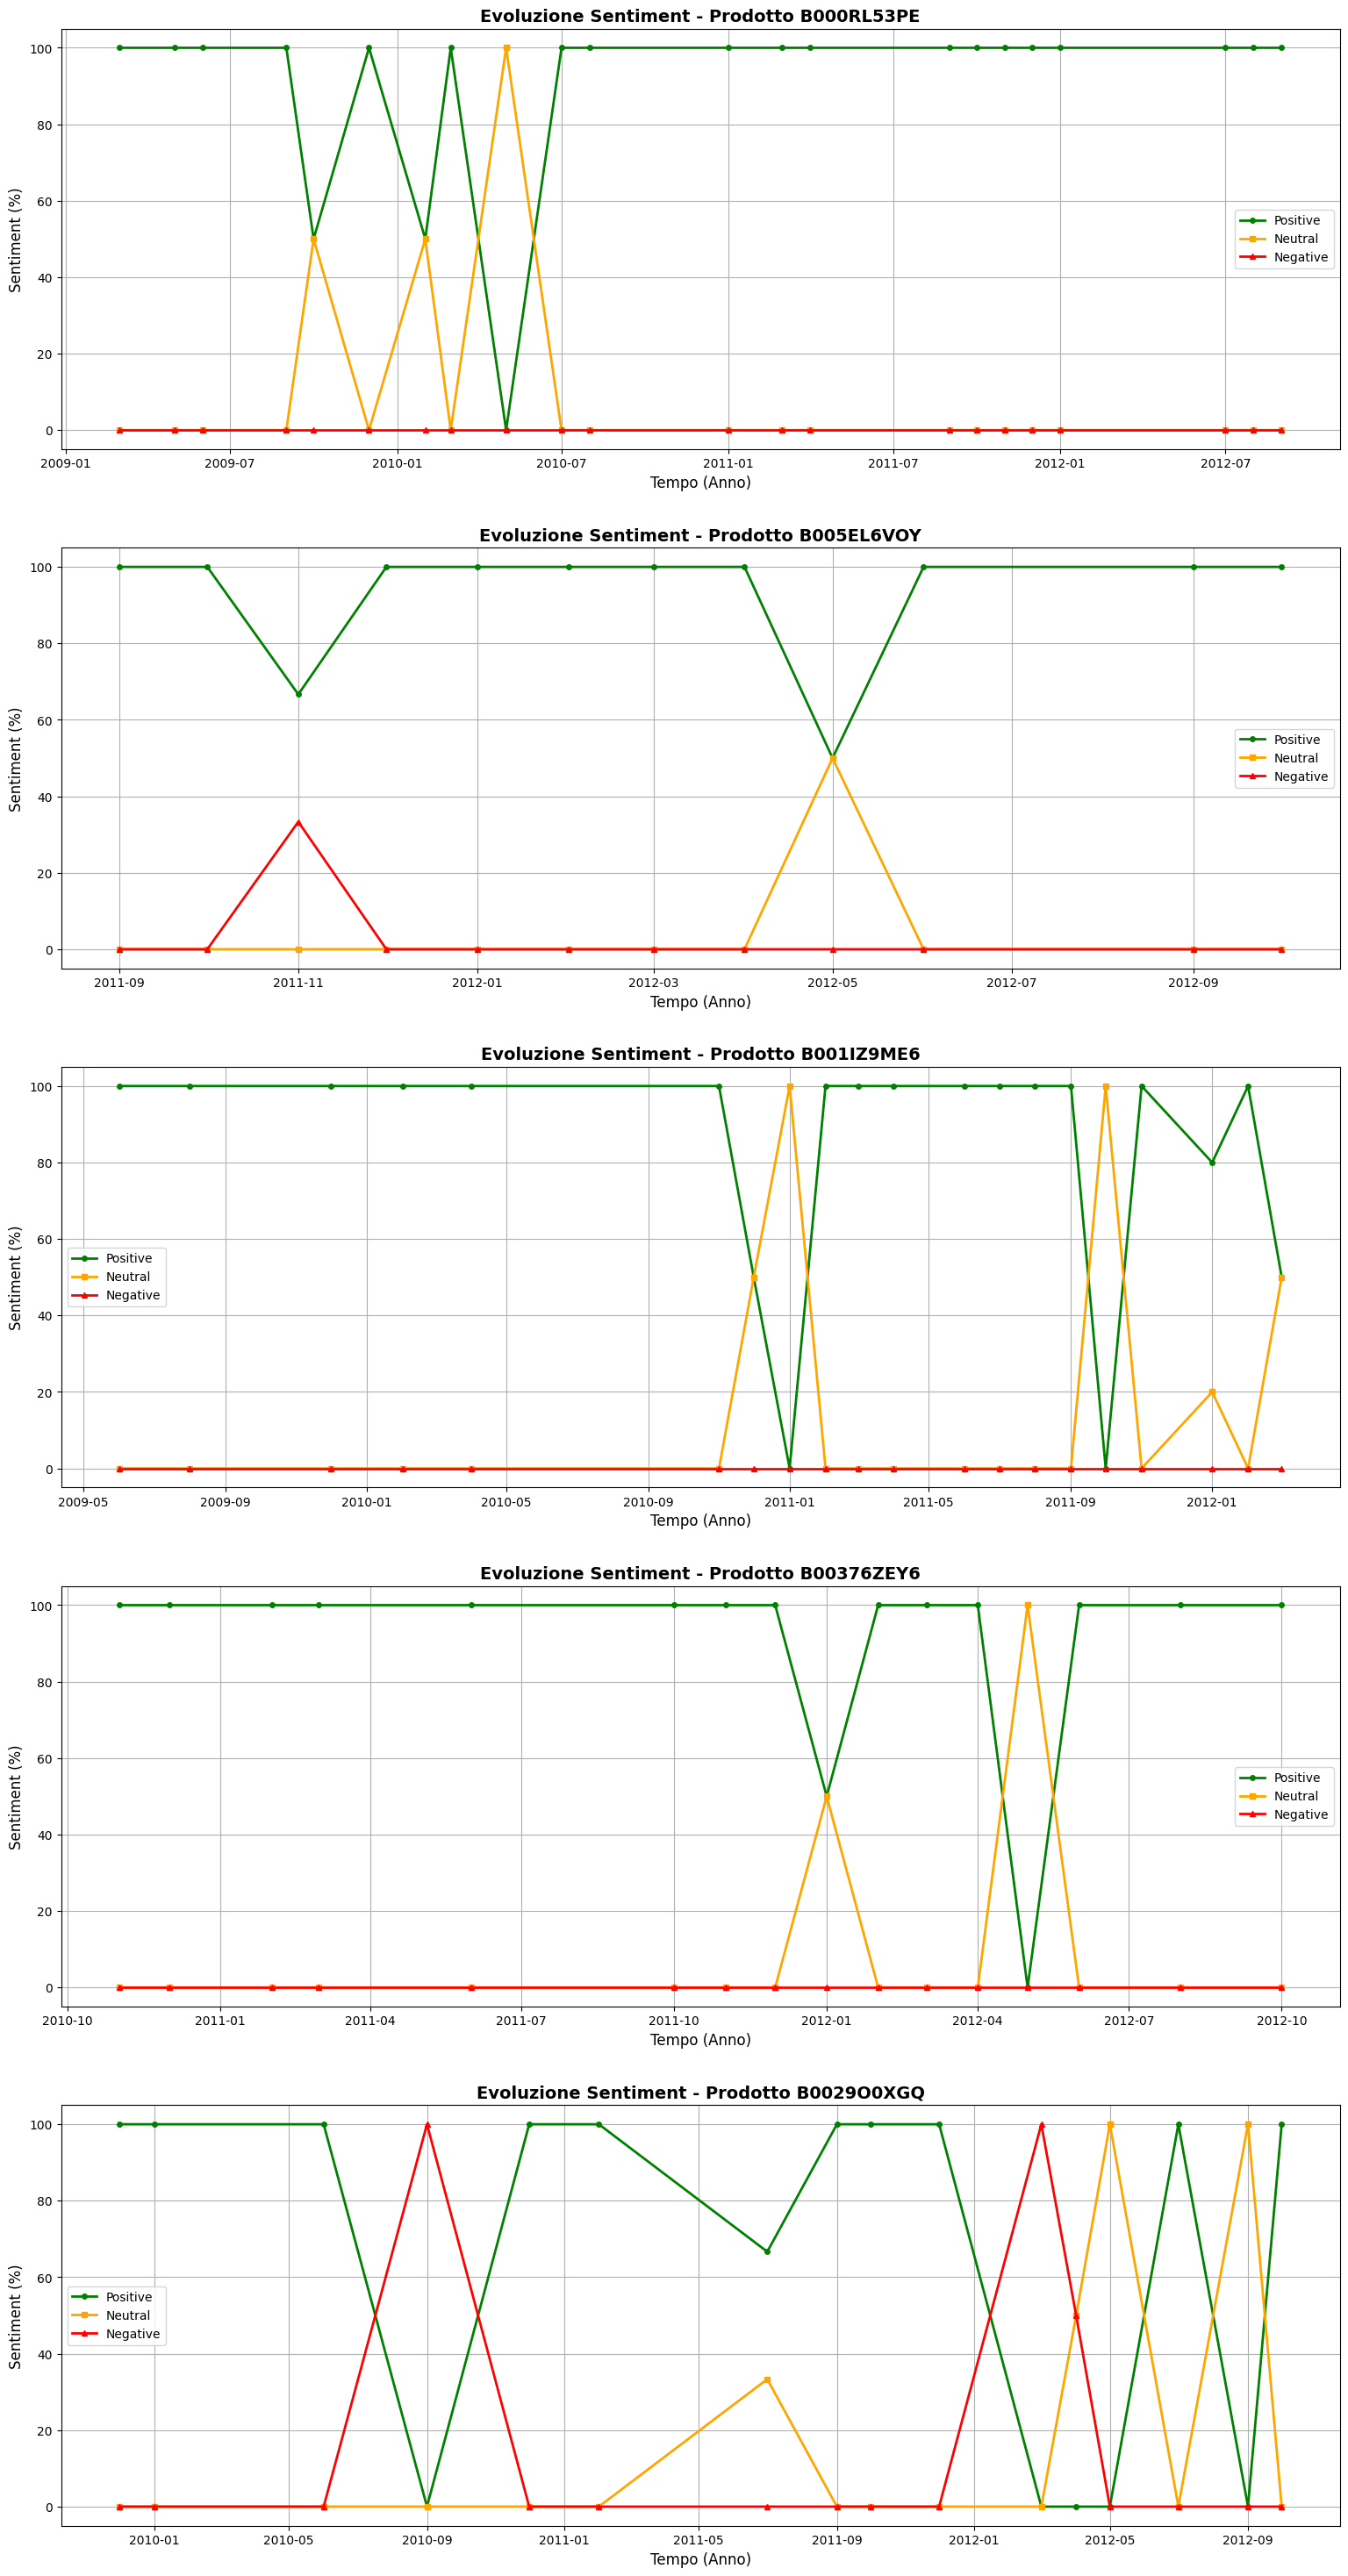

In [ ]:
fig, axes = plt.subplots(len(temporal_data), 1, 
                         figsize=(16, 6 * len(temporal_data)), 
                        squeeze=False)

for idx, (product_id, data) in enumerate(temporal_data.items()):
    ax = axes[idx, 0]
    
    # Plot dei tre sentiment
    ax.plot(data.index, data['positive'], 'g-o', label='Positive', linewidth=2, markersize=4)
    ax.plot(data.index, data['neutral'], color='orange', marker='s', label='Neutral', linewidth=2, markersize=4)
    ax.plot(data.index, data['negative'], 'r-^', label='Negative', linewidth=2, markersize=4)
    
    ax.set_title(f'Evoluzione Sentiment - Prodotto {product_id}', fontsize=14, fontweight='bold')
    ax.set_xlabel('Tempo (Anno)', fontsize=12)
    ax.set_ylabel('Sentiment (%)', fontsize=12)
    ax.legend(loc='best')
    ax.grid(True, which='both')

plt.tight_layout(pad=3.0)

### 5c) Identificazione delle Anomalie Mensili nel Sentiment

In [ ]:
def detect_sentiment_anomalies(temporal_df, threshold=20):
    """
    Identifica anomalie/cambiamenti significativi nel sentiment
    """
    anomalies = []
    
    # Calcola le variazioni month-over-month
    for sentiment_type in ['positive', 'neutral', 'negative']:
        if sentiment_type in temporal_df.columns:
            # Calcola la differenza percentuale rispetto al mese precedente
            diff = temporal_df[sentiment_type].diff()
            
            # Identifica variazioni superiori alla soglia
            significant_changes = diff[abs(diff) > threshold]
            
            for period, change in significant_changes.items():
                anomalies.append({
                    'period': period.strftime('%Y-%m'),
                    'sentiment_type': sentiment_type,
                    'change': change,
                    'previous_value': temporal_df.loc[period, sentiment_type] - change,
                    'current_value': temporal_df.loc[period, sentiment_type]
                })
    
    return anomalies

# Analizza anomalie per ogni prodotto
print(f"Soglia: variazioni > 20% rispetto al mese precedente")

all_anomalies = {}

for product_id, data in temporal_data.items():
    anomalies = detect_sentiment_anomalies(data, threshold=20)
    all_anomalies[product_id] = anomalies
    
    if anomalies:
        print(f"\n\nProdotto: {product_id}")
        print(f"Trovate {len(anomalies)} anomalie:\n")
        
        anomalies.sort(key=lambda x: x['period'])
        for anom in anomalies:
            direction = "UP" if anom['change'] > 0 else "DOWN"
            print(f"{anom['period']}: sentiment {anom['sentiment_type'].upper()} {direction} "
                f"{abs(anom['change']):.1f}% "
                f"({anom['previous_value']:.1f}% -> {anom['current_value']:.1f}%)")
    else:
        print(f"\nProdotto: {product_id}")
        print(f"Nessuna anomalia rilevata (andamento stabile)")

Soglia: variazioni > 20% rispetto al mese precedente


Prodotto: B000RL53PE
Trovate 12 anomalie:

2009-10: sentiment POSITIVE DOWN 50.0% (100.0% -> 50.0%)
2009-10: sentiment NEUTRAL UP 50.0% (0.0% -> 50.0%)
2009-12: sentiment POSITIVE UP 50.0% (50.0% -> 100.0%)
2009-12: sentiment NEUTRAL DOWN 50.0% (50.0% -> 0.0%)
2010-02: sentiment POSITIVE DOWN 50.0% (100.0% -> 50.0%)
2010-02: sentiment NEUTRAL UP 50.0% (0.0% -> 50.0%)
2010-03: sentiment POSITIVE UP 50.0% (50.0% -> 100.0%)
2010-03: sentiment NEUTRAL DOWN 50.0% (50.0% -> 0.0%)
2010-05: sentiment POSITIVE DOWN 100.0% (100.0% -> 0.0%)
2010-05: sentiment NEUTRAL UP 100.0% (0.0% -> 100.0%)
2010-07: sentiment POSITIVE UP 100.0% (0.0% -> 100.0%)
2010-07: sentiment NEUTRAL DOWN 100.0% (100.0% -> 0.0%)


Prodotto: B005EL6VOY
Trovate 8 anomalie:

2011-11: sentiment POSITIVE DOWN 33.3% (100.0% -> 66.7%)
2011-11: sentiment NEGATIVE UP 33.3% (0.0% -> 33.3%)
2011-12: sentiment POSITIVE UP 33.3% (66.7% -> 100.0%)
2011-12: sentiment NEGATIVE DOWN 33

### 5d) Discussione: Cause delle Variazioni e Adattamento del Sistema

L'analisi dei 5 prodotti "top" rivela un pattern chiaro: *non* si tratta di *prodotti popolari*, ma di *prodotti sporadici* che hanno ricevuto pochissime recensioni, anche se tutte con punteggio 5.0 (da cui l'anomala media di 5.00).

1. Analisi delle Cause: Rumore Statistico, non Trend

Osservando i grafici e l'elenco delle anomalie, vediamo cambiamenti estremi e costanti: `POSITIVE DOWN 100.0% (100.0% -> 0.0%)` seguito poi da `POSITIVE UP 100.0% (0.0% -> 100.0%)`.

* Causa Primaria (Basso Volume): Questa volatilità non è un "cambiamento nel trend di mercato". È un artefatto statistico causato da un denominatore piccolissimo.

    * Se un prodotto riceve una recensione in un mese ed è positiva, il sentiment è 100% positivo.

    * Se nel mese successivo riceve una recensione ed è negativa (es. B0029O0XGQ nel 2010-09), il sentiment crolla a 0% positivo e sale a 100% negativo.

    * Il codice rileva correttamente un "cambiamento > 20%", ma l'anomalia non è statisticamente significativa. I picchi da 33.3% e 50.0% confermano questa ipotesi (indicando un totale di 3 o 2 recensioni in quei mesi).

* Causa Secondaria (Prodotti di Nicchia): Si tratta probabilmente di prodotti di nicchia o specifici (es. ricambi, accessori particolari) che vengono acquistati e recensiti molto di rado.

2. Come il Sistema di Raccomandazione Dovrebbe Adattarsi

Questa analisi dimostra che sia il sistema di raccomandazione principale sia lo script di anomalie hanno difetti che devono essere corretti per gestire dati sparsi (sparse data).

* Adattamento 1: "Riparare" la Logica di Raccomandazione (Non fidarsi delle medie semplici)

    * Il problema principale è che il sistema ibrido (dell'esercizio precedente) potrebbe erroneamente promuovere questi prodotti solo perché hanno un avg_score di 5.0.

    * Soluzione: Introdurre la "Fiducia" (Confidence). Non si dovrebbe trattare un punteggio di 5.0 (con 10 recensioni) come migliore di un 4.8 (con 5000 recensioni).

    * Tecnica: Sostituire la media semplice con un punteggio di fiducia bayesiano (Bayesian Average) o un Intervallo di Confidenza Wilson (Wilson Score). Queste formule "scontano" il punteggio dei prodotti con poche recensioni, "tirandoli" verso la media globale del dataset.

    * Impatto: Un prodotto 5.0/10 recensioni verrebbe classificato molto più in basso di un 4.8/5000, risolvendo il problema alla radice.

* Adattamento 2: "Riparare" lo Script di Rilevamento Anomalie

    * Lo script attuale è "rumoroso" perché non distingue tra un cambiamento basato su 2 recensioni e uno basato su 2000.

    * Soluzione: Aggiungere una Soglia Minima di Volume. Bisogna modificare la funzione `detect_sentiment_anomalies` per ignorare i mesi che non raggiungono un volume minimo di recensioni.

    * Tecnica: Nel Blocco 5a (calcolo temporale), bisognerebbe salvare anche il `monthly_total` (il conteggio totale delle recensioni in quel mese). Lo script di anomalia dovrebbe attivarsi solo se (abs(diff) > threshold) E (monthly_total > N) (es. N > 20 recensioni).

    * Impatto: Questo filtrerebbe il 90% delle anomalie "rumorose" viste, e farebbe emergere solo i veri cambiamenti di trend nei prodotti ad alto volume.

* Adattamento 3: Penalizzazione Temporale (Solo per Dati Affidabili)

    * L'idea di una penalizzazione basata sul trend (w_trend) discussa in precedenza rimane valida, ma solo dopo aver implementato l'Adattamento 2.

    * Soluzione: Applichiamo una penalizzazione sul final_score solo se un prodotto mostra un trend negativo e quel trend è basato su un volume di dati statisticamente significativo.

    * Impatto: Il sistema diventerebbe robusto: ignorerebbe il rumore dei prodotti di nicchia, ma reagirebbe rapidamente (es. riducendo le raccomandazioni) per un prodotto popolare che sta improvvisamente ricevendo un'ondata di recensioni negative reali (es. a causa di un lotto difettoso).